# 08 · Jets with FastJet

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/08_jets_fastjet.ipynb)

**Time:** 45 minutes · **Needs:** any setup with FastJet (Python) · **Data:** `auau_stats`: the hadron files (0.2 GB), `pp_ref`: the jet hadrons (43 MB), both downloaded once

Jets are the sprays of hadrons that hard partons become. In a central Au+Au collision a jet sits
on top of about 1,400 soft charged hadrons at midrapidity, and the partons lose energy on their
way through the plasma. This tutorial finds jets in the hadrons of tutorial 05 with
[FastJet](https://fastjet.fr), and:
- subtracts the background with jet areas and the background density ρ;
- measures the background's fluctuations with random cones and by embedding a jet into a
  background it never touched;
- shows why low-$p_T$ jets in Au+Au are mostly fake;
- compares the cross-section-weighted jet spectrum with the p+p reference: a jet suppression
  inside the model;
- compares a substructure observable, the SoftDrop $z_g$, in Au+Au and p+p;
- measures how much of the jet's lost energy comes back into the jet cone through the medium response.

Everything here is a comparison inside the model, not with measured data.

Reference pages: [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/), [Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/).

> **Work in progress: examples, not vetted physics.** The tutorials show how to run the
> simulation and use its outputs. The data sets are small, so the statistics are low, and
> the analyses have not been checked to the standard of a publication: treat every number
> and figure as an illustration, not as a physics result.

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/). In Colab they are
# fetched first, with the jetscape readers; locally nothing is installed.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("_common"):
    subprocess.run("curl -sL https://codeload.github.com/jhputschke/js-contrib/tar.gz/refs/heads/main"
                   " | tar xz --strip-components=3 js-contrib-main/tutorials/pyjetscape",
                   shell=True, check=True)
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
te.colab_install()
env = te.setup()

tutorials v2.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


In [2]:
ok, missing = te.meets(['analysis', 'fastjet'], env.caps)
assert ok, f"this tutorial needs {missing}: see 01_check_setup.ipynb"

## 1. FastJet in Python, and the data

The `fastjet` package from PyPI (scikit-hep) ships the FastJet library with two interfaces:

- the **classic** interface: lists of `PseudoJet`, as in C++. It has jet areas, background
  estimators and selectors, which the subtraction in Au+Au needs.
- the **array** interface: awkward arrays of many events at once, clustered in C++ without a
  Python loop. It has no areas, but it is fast, and it wraps four routines of fjcontrib, SoftDrop
  among them.

We use the classic interface for the Au+Au events and the array interface for the jets of the jet
hadrons alone and of p+p. The data: the 120 Au+Au events of tutorial 05 and their vacuum reference,
4,500 p+p events with the same p̂T windows and the same cut on the partons, showered by MATTER without
a medium and hadronized the same way (`run_prod_vacuum.py`).

In [3]:
import time
from importlib.metadata import version
import numpy as np
import fastjet as fj
import awkward as ak
from jetscape.hadrons_h5 import CHARGED, HadronFile, HadronFileReader

aa = HadronFileReader(str(te.fetch("auau_stats", include=["*_hadrons_*.h5"], quiet=True)))
pp = HadronFileReader(str(te.fetch("pp_ref", include=["*_hadrons_jet_frag.h5"], quiet=True)))
print(f"fastjet {version('fastjet')}, awkward {ak.__version__}")
print(f"Au+Au: {aa.n_events} events, tags {aa.tags()} | p+p: {pp.n_events} events, tags {pp.tags()}")
for name, rd in (("Au+Au", aa), ("p+p", pp)):
    print(f"  {name}: windows {rd.pthat_bins.tolist()}, events per window "
          f"{[len(rd.pthat_bin_events(k)) for k in range(3)]}, fragmentations per event {rd.n_frag(0)}")

fastjet 3.5.1.5, awkward 2.8.11
Au+Au: 120 events, tags ('bulk_jet', 'bulk_bg', 'jet_frag') | p+p: 4500 events, tags ('jet_frag',)
  Au+Au: windows [[10.0, 20.0], [20.0, 30.0], [30.0, 50.0]], events per window [40, 40, 40], fragmentations per event 10
  p+p: windows [[10.0, 20.0], [20.0, 30.0], [30.0, 50.0]], events per window [1500, 1500, 1500], fragmentations per event 10


**The conventions** (those of [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/#2-conventions)):

- **Particles:** charged hadrons with $|\eta| < 1.5$ and $p_T > 0.15$ GeV, clustered as massless
  ($E = |\vec p|$), so that rapidity equals pseudorapidity.
- **Jets:** anti-$k_T$ with $R = 0.4$, inside $|\eta_\text{jet}| < 1.5 - R = 1.1$. Anti-$k_T$ clusters
  around the hardest particles first, so a hard jet is a cone of radius $R$.
- **Areas:** active areas with explicit ghosts. FastJet adds a fine grid of infinitely soft "ghost"
  particles (one per 0.005 in $\eta$–$\varphi$); a jet's area $A$ is the number of ghosts it contains
  times 0.005. A hard jet has $A \approx \pi R^2 = 0.50$.
- **ρ:** the median of $p_T/A$ over the $k_T$ jets ($R = 0.4$) in $|\eta| < 1.1$, without the two
  hardest. The median is barely moved by the few jets that contain a real hard jet. Each jet is then
  corrected by $p_T - \rho A$.

`user_index` tags each particle. We give the jet's fragments indices from 1,000,000 on, so that we
always know how much of a jet's $p_T$ comes from the jet itself.

In [4]:
ETA_MAX, R, PT_MIN = 1.5, 0.4, 0.15
JET_ETA = ETA_MAX - R
JET_DEF = fj.JetDefinition(fj.antikt_algorithm, R)
KT_DEF = fj.JetDefinition(fj.kt_algorithm, R)
AREA_DEF = fj.AreaDefinition(fj.active_area_explicit_ghosts, fj.GhostedAreaSpec(ETA_MAX, 1, 0.005))
RHO_SEL = (~fj.SelectorNHardest(2)) * fj.SelectorAbsRapMax(JET_ETA)     # applied right to left
JET_SEL = fj.SelectorAbsRapMax(JET_ETA)
CHARGED_PID = np.array(CHARGED)
FRAG = 1_000_000                       # user_index offset of the jet's fragments

def accepted(p, pid):
    """The particles we cluster: charged, |eta| < 1.5, pT > 0.15 GeV."""
    pt = np.hypot(p[:, 1], p[:, 2])
    eta = np.arcsinh(p[:, 3] / np.maximum(pt, 1e-12))
    return (np.abs(eta) < ETA_MAX) & (pt > PT_MIN) & np.isin(np.abs(pid), CHARGED_PID)

def pseudojets(p, pid, offset=0):
    """Massless PseudoJets of the accepted hadrons; user_index = offset + row."""
    p = np.asarray(p, dtype=np.float64)
    out = []
    for i in np.flatnonzero(accepted(p, pid)):
        pj = fj.PseudoJet(p[i, 1], p[i, 2], p[i, 3], float(np.linalg.norm(p[i, 1:])))
        pj.set_user_index(int(i) + offset)
        out.append(pj)
    return out

def cluster(parts, pt_min=5.0):
    """anti-kT jets with areas (raw pT > pt_min, |eta| < 1.1, hardest first), rho and its spread.
    Returns the ClusterSequence too: the jets' constituents live only as long as it does."""
    cs = fj.ClusterSequenceArea(parts, JET_DEF, AREA_DEF)
    cs_kt = fj.ClusterSequenceArea(parts, KT_DEF, AREA_DEF)
    bge = fj.JetMedianBackgroundEstimator(RHO_SEL, KT_DEF, AREA_DEF)
    bge.set_use_area_4vector(False)            # the scalar area, the one in pT - rho A
    bge.set_jets(cs_kt.inclusive_jets())
    jets = fj.sorted_by_pt(JET_SEL(cs.inclusive_jets(pt_min)))
    return jets, bge.rho(), bge.sigma(), (cs, cs_kt)

def frag_pt(jet):
    """The pT a jet's constituents from the jet's own fragments carry."""
    return sum(c.pt() for c in jet.constituents() if c.user_index() >= FRAG)

# FastJet prints its banner (and asks to be cited) the first time it clusters: here.
_ = fj.ClusterSequence([fj.PseudoJet(1.0, 0.0, 0.0, 1.0)], JET_DEF).inclusive_jets()

#--------------------------------------------------------------------------
#                         FastJet release 3.5.1
#                 M. Cacciari, G.P. Salam and G. Soyez                  
#     A software package for jet finding and analysis at colliders      
#                           https://fastjet.fr                           
#	                                                                      
# Please cite EPJC72(2012)1896 [arXiv:1111.6097] if you use this package
# for scientific work and optionally PLB641(2006)57 [hep-ph/0512210].   
#                                                                       
# FastJet is provided without warranty under the GNU GPL v2 or higher.  
# It uses T. Chan's closest pair algorithm, S. Fortune's Voronoi code,
# CGAL and 3rd party plugin jet algorithms. See COPYING file for details.
#--------------------------------------------------------------------------


## 2. One Au+Au event

Take the first event of the highest window (p̂T 30–50 GeV) and its oversample 0: `bulk_jet` (the
medium, with the jet's wake) plus fragmentation 0 of its jet. Its two hard partons:

In [5]:
import pandas as pd
g = int(aa.pthat_bin_events(2)[0])
ini = aa.event_info(g).initiators()          # shower, pid, pstat, px, py, pz, E, ...
ini_pt = np.hypot(ini[:, 3], ini[:, 4])
lead2 = np.argsort(ini_pt)[::-1][:2]
print(f"event {g}: pTHat = {aa.event_info(g).pthat:.1f} GeV; hardest initiators: " + "; ".join(
    f"pT {ini_pt[i]:.1f} GeV at eta {np.arcsinh(ini[i, 5] / ini_pt[i]):+.2f}, phi {np.arctan2(ini[i, 4], ini[i, 3]):+.2f}"
    for i in lead2))

ev = aa.jet_event(g, 0)
is_frag = ev["origin"] == 1                   # 0: bulk_jet, 1: jet_frag
parts = pseudojets(ev["p"][~is_frag], ev["pid"][~is_frag]) + pseudojets(ev["p"][is_frag], ev["pid"][is_frag], FRAG)
jets, rho, sigma_rho, keep = cluster(parts)
print(f"{len(parts)} charged particles clustered; rho = {rho:.1f} GeV per unit area (spread sigma = {sigma_rho:.1f}),"
      f" so rho pi R^2 = {rho * np.pi * R**2:.1f} GeV")
one = pd.DataFrame([{"pT raw": j.pt(), "area": j.area(), "rho A": rho * j.area(), "pT - rho A": j.pt() - rho * j.area(),
                     "from fragments": frag_pt(j), "eta": j.eta(), "phi": j.phi_std()} for j in jets[:8]])
one.round(2)

event 2: pTHat = 36.9 GeV; hardest initiators: pT 36.3 GeV at eta +0.15, phi +2.65; pT 35.5 GeV at eta -0.64, phi -0.80
2063 charged particles clustered; rho = 64.0 GeV per unit area (spread sigma = 5.5), so rho pi R^2 = 32.2 GeV


,pT raw,area,rho A,pT - rho A,from fragments,eta,phi
0,59.15,0.50,32.26,26.89,21.51,-0.71,-0.73
1,44.33,0.57,36.78,7.55,0.00,-0.07,-2.15
2,44.27,0.53,33.88,10.39,0.64,0.02,2.08
3,43.94,0.51,32.59,11.35,3.81,0.07,2.75
4,43.88,0.44,28.07,15.81,1.09,1.03,1.63
5,42.60,0.57,36.46,6.14,0.16,0.29,0.66
6,40.32,0.46,29.68,10.64,0.00,-0.77,1.99
7,39.04,0.50,32.26,6.78,0.00,0.50,-1.26


**What to notice.**

- **Every jet carries about 30 GeV of background.** ρ is about 64 GeV per unit area, and a jet of
  area 0.5 collects $\rho A \approx 30$ GeV of soft hadrons that have nothing to do with it. The raw
  $p_T$ of the eight hardest jets is 40–60 GeV, but most of them hold no more than 1 GeV of the jet's
  fragments.
- **One jet stands out after subtraction**: the hardest, at about 27 GeV, with about 22 GeV from
  fragments. It points along the second parton ($\eta \approx -0.6$, $\varphi \approx -0.8$). The
  few GeV it has beyond its fragments are background fluctuation and medium response.
- **The other parton's jet is hard to find.** Near $\varphi \approx 2.7$ there is a jet with only
  about 4 GeV of fragments: most of that parton's 36 GeV went elsewhere. This event gave about
  49 GeV to the fluid (the event table of tutorial 05, row 2). Jets with at most 1 GeV
  of fragments, *fake* jets made by upward fluctuations of the background, reach 6–16 GeV here. In one
  event, nothing tells a real jet of 10 GeV from a fake one.

## 3. Background fluctuations: random cones and embedding

ρ is an average. Around it, the background fluctuates from place to place: a cone of radius 0.4
holds a few GeV more or less than $\rho\pi R^2$. These fluctuations smear every jet's $p_T$, and they
make the fake jets. The model gives us two clean ways to measure them, because every jet event has a
twin without the jet (`bulk_bg`):

| event | hadrons | measures |
|---|---|---|
| **bkg** | `bulk_bg` oversample $k$ | ρ, random cones, fake jets |
| **bkg + jet** | `bulk_bg` oversample $k$ + the jet's fragments | embedding: a jet in a background it did not touch |
| **bkg + wake + jet** | `bulk_jet` oversample $k$ + the same fragments | the full event, with the medium response |

- A **random cone** is a cone of radius $R$ at a random place in a background event:
  $\delta p_T = \sum_\text{cone} p_T - \rho\pi R^2$.
- **Embedding**: we find the jets of the fragments alone (the *reference* jets), and match each to
  the jet of the combined event that holds most of its fragments' $p_T$. Then
  $\delta p_T = (p_T - \rho A) - p_{T,\text{ref}}$.

All three events are clustered for every event and oversample. **To keep the runtime near a minute,
we use 5 of the 10 oversamples of each event** (`N_OS`; with 10 it takes twice as long and the
results are the same within errors).

In [6]:
N_OS = 5                                        # oversamples per event (of 10)
rng = np.random.default_rng(2026)               # random cones
jets_rec = {leg: [] for leg in ("full", "emb", "bkg")}   # event, oversample, pT, area, rho, fragment pT
rho_rec = {leg: [] for leg in ("full", "emb", "bkg")}
cones, matched = [], []

def match(ref_idx, jets):
    """The jet with the largest pT from the reference jet's fragments, and that pT."""
    best, best_pt = None, 0.0
    for j in jets:
        s = sum(c.pt() for c in j.constituents() if c.user_index() in ref_idx)
        if s > best_pt:
            best, best_pt = j, s
    return best, best_pt

t0 = time.time()
for e in aa.events():
    for k in range(N_OS):
        full = aa.jet_event(e, k)                 # bulk_jet k + jet_frag k
        bkg = aa.background_event(e, k)           # bulk_bg k of the event's background
        fr = full["origin"] == 1
        frag = pseudojets(full["p"][fr], full["pid"][fr], FRAG)
        cs_ref = fj.ClusterSequence(frag, JET_DEF)
        refs = [(j.pt(), {c.user_index() for c in j.constituents()})
                for j in fj.sorted_by_pt(JET_SEL(cs_ref.inclusive_jets(10.0)))]
        bkg_parts = pseudojets(bkg["p"], bkg["pid"])
        legs = {"full": pseudojets(full["p"][~fr], full["pid"][~fr]) + frag,
                "emb": bkg_parts + frag, "bkg": bkg_parts}
        found = {}
        for leg, parts in legs.items():
            jets, rho, _, keep = cluster(parts)
            rho_rec[leg].append(rho)
            jets_rec[leg] += [(e, k, j.pt(), j.area(), rho, frag_pt(j)) for j in jets]
            found[leg] = (jets, rho, keep)
        # one random cone per background sample, at a random place inside |eta| < 1.1
        eta0, phi0 = rng.uniform(-JET_ETA, JET_ETA), rng.uniform(-np.pi, np.pi)
        p = np.asarray(bkg["p"], dtype=np.float64)[accepted(np.asarray(bkg["p"], dtype=np.float64), bkg["pid"])]
        pt = np.hypot(p[:, 1], p[:, 2])
        dr = np.hypot(np.arcsinh(p[:, 3] / pt) - eta0, np.mod(np.arctan2(p[:, 2], p[:, 1]) - phi0 + np.pi, 2 * np.pi) - np.pi)
        cones.append(pt[dr < R].sum() - found["bkg"][1] * np.pi * R**2)
        # embedding: each reference jet above 10 GeV, matched in bkg + jet and in bkg + wake + jet
        for pt_ref, idx in refs:
            row = [e, k, pt_ref]
            for leg in ("emb", "full"):
                jets, rho, _ = found[leg]
                best, share = match(idx, jets)
                row += [np.nan, 0.0] if best is None else [best.pt() - rho * best.area() - pt_ref, share / pt_ref]
            matched.append(row)
print(f"{aa.n_events} events x {N_OS} oversamples x 3 events clustered in {time.time() - t0:.0f} s")
jets_rec = {leg: np.array(v) for leg, v in jets_rec.items()}
rho_rec = {leg: np.array(v) for leg, v in rho_rec.items()}
cones = np.array(cones)
matched = pd.DataFrame(matched, columns=["event", "k", "pt_ref", "dpt_emb", "share_emb", "dpt_full", "share_full"])
print(f"{len(matched)} reference jets above 10 GeV in {aa.n_events * N_OS} samples")

120 events x 5 oversamples x 3 events clustered in 39 s
252 reference jets above 10 GeV in 600 samples


rho (bkg): mean 61.3, spread over samples 8.4 GeV
random cones:  <dpT> = +0.99 +- 0.23 GeV, width 5.55 GeV
embedded jets: <dpT> = +0.18 +- 0.34 GeV, width 5.43 GeV (99% of 252 reference jets matched in both events)
  fragments' pT the matched embedded jet keeps: 98.6%
  the jet raises rho a little: rho(bkg + jet) - rho(bkg) = +0.61 GeV per unit area
full events:   <dpT> = +1.02 GeV, width 5.93 GeV
full - embedded, jet by jet: +0.83 +- 0.49 GeV


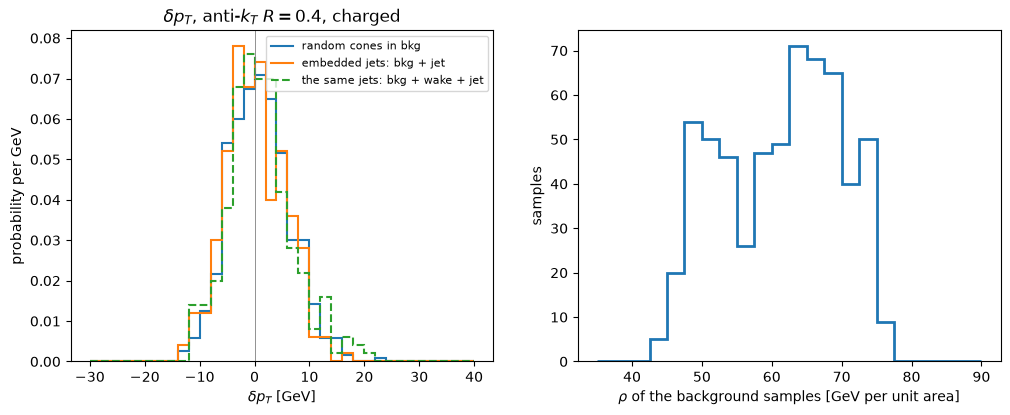

In [7]:
import hist
import mplhep as mh
import matplotlib.pyplot as plt

ok = (matched["share_emb"] > 0.5) & (matched["share_full"] > 0.5)   # found in both events
d_emb, d_full = matched.loc[ok, "dpt_emb"].to_numpy(), matched.loc[ok, "dpt_full"].to_numpy()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
b = np.linspace(-30, 40, 36)
h = lambda x: hist.Hist(hist.axis.Variable(b, label=r"$\delta p_T$ [GeV]")).fill(x)
mh.histplot(h(cones) / len(cones) / np.diff(b), ax=ax, label="random cones in bkg", flow="none")
mh.histplot(h(d_emb) / len(d_emb) / np.diff(b), ax=ax, label="embedded jets: bkg + jet", flow="none")
mh.histplot(h(d_full) / len(d_full) / np.diff(b), ax=ax, label="the same jets: bkg + wake + jet", flow="none", ls="--")
ax.axvline(0, color="0.5", lw=0.6)
ax.set(ylabel="probability per GeV", title=r"$\delta p_T$, anti-$k_T$ $R = 0.4$, charged")
ax.legend(fontsize=8)
ax2.hist(rho_rec["bkg"], np.linspace(35, 90, 23), histtype="step", lw=2)
ax2.set(xlabel=r"$\rho$ of the background samples [GeV per unit area]", ylabel="samples")

print(f"rho (bkg): mean {rho_rec['bkg'].mean():.1f}, spread over samples {rho_rec['bkg'].std():.1f} GeV")
print(f"random cones:  <dpT> = {cones.mean():+.2f} +- {cones.std() / np.sqrt(len(cones)):.2f} GeV, width {cones.std():.2f} GeV")
print(f"embedded jets: <dpT> = {d_emb.mean():+.2f} +- {d_emb.std() / np.sqrt(len(d_emb)):.2f} GeV, width {d_emb.std():.2f} GeV"
      f" ({ok.mean():.0%} of {len(matched)} reference jets matched in both events)")
print(f"  fragments' pT the matched embedded jet keeps: {matched.loc[ok, 'share_emb'].mean():.1%}")
print(f"  the jet raises rho a little: rho(bkg + jet) - rho(bkg) = {np.mean(rho_rec['emb'] - rho_rec['bkg']):+.2f} GeV per unit area")
print(f"full events:   <dpT> = {d_full.mean():+.2f} GeV, width {d_full.std():.2f} GeV")
diff = d_full - d_emb
print(f"full - embedded, jet by jet: {diff.mean():+.2f} +- {diff.std() / np.sqrt(len(diff)):.2f} GeV")

**What to notice.**

- **The width is the jet resolution: about 5.5 GeV** for random cones and embedded jets alike. It
  is the fluctuation of the 30 GeV of background in a cone of radius 0.4, and every jet in central
  Au+Au is smeared by it. The distributions have a longer tail to positive $\delta p_T$: upward
  fluctuations of soft hadrons are larger than downward ones.
- **The subtraction is right on average, within about 1 GeV.** Random cones come out +1 GeV high:
  the median ρ is a little below the mean density, because the $p_T/A$ of the $k_T$ jets has a tail
  to high values. Embedded jets come out lower, near zero: the jet itself raises ρ a little (printed),
  and their error is ±0.3 GeV.
- **The jet is not lost in the background**: the matched jet keeps about 99 % of its fragments' $p_T$.
- **The full event gives about 0.8 GeV more than the embedding**, jet by jet, with an error of 0.5 GeV:
  the same fragments, but in the background with the jet's wake. Section 7 measures this medium
  response directly.
- **ρ changes from background to background**, from about 45 to 77 GeV per unit area: the 20 collisions
  differ in multiplicity (tutorial 05). Every event needs its own ρ.

## 4. Fake jets

The background alone makes jets too. After subtraction they scatter around zero with the width of
the random cones, and their upper tail reaches about 20 GeV, rarely beyond. Per event, in the highest p̂T window,
compare the subtracted jets of the three events with the reference jets of the fragments alone:

pT - rho A 10-15 GeV: fake jets per event 1.145, all jets of the full event 1.365
pT - rho A 15-20 GeV: fake jets per event 0.160, all jets of the full event 0.390
pT - rho A 20-25 GeV: fake jets per event 0.020, all jets of the full event 0.265
pT - rho A 25-30 GeV: fake jets per event 0.000, all jets of the full event 0.145


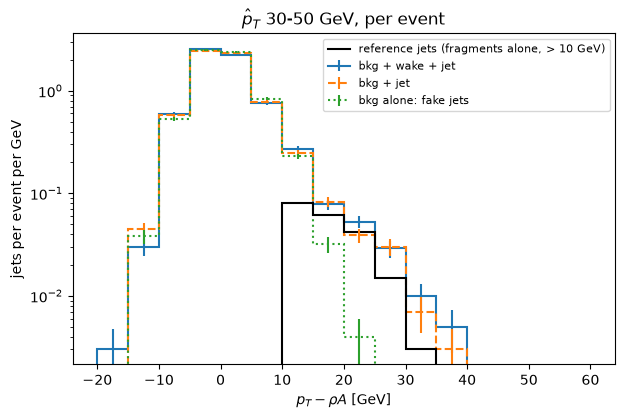

In [8]:
edges = np.arange(-20, 61, 5.0)
win2 = aa.pthat_bin_events(2)
def per_event_spectrum(rec, events):
    """Subtracted anti-kT jets per event (each event: the mean over its N_OS oversamples)."""
    sel = np.isin(rec[:, 0].astype(int), events)
    h = hist.Hist(hist.axis.Variable(edges, label=r"$p_T - \rho A$ [GeV]"), storage=hist.storage.Weight())
    h.fill(rec[sel, 2] - rec[sel, 4] * rec[sel, 3], weight=np.full(sel.sum(), 1.0 / (N_OS * len(events))))
    return h

fig, ax = plt.subplots(figsize=(7, 4.3))
for leg, label, ls in (("full", "bkg + wake + jet", "-"), ("emb", "bkg + jet", "--"), ("bkg", "bkg alone: fake jets", ":")):
    mh.histplot(per_event_spectrum(jets_rec[leg], win2) / np.diff(edges), ax=ax, label=label, flow="none", ls=ls)
ref_pt = matched.loc[np.isin(matched["event"], win2), "pt_ref"]
ax.stairs(np.histogram(ref_pt, edges)[0] / (N_OS * len(win2)) / np.diff(edges), edges, color="k", lw=1.5,
          label="reference jets (fragments alone, > 10 GeV)")
ax.set(yscale="log", ylabel="jets per event per GeV", title=r"$\hat p_T$ 30-50 GeV, per event")
ax.legend(fontsize=8)
fake = per_event_spectrum(jets_rec["bkg"], win2).values()
real = per_event_spectrum(jets_rec["full"], win2).values()
for lo in (10, 15, 20, 25):
    i = np.searchsorted(edges, lo)
    print(f"pT - rho A {edges[i]:.0f}-{edges[i + 1]:.0f} GeV: fake jets per event {fake[i]:.3f}, "
          f"all jets of the full event {real[i]:.3f}")

**What to notice.**

- **Below 15 GeV, most jets are fake.** At 10–15 GeV there are about 1.4 jets per event in the
  full event, and 1.1 of them come from the background alone. At 15–20 GeV the fakes are still about
  40 %; above 20 GeV they are below 10 %, and above 25 GeV none appear in these 600 background samples.
- **Above 20 GeV the full event has more jets than the reference.** The ±5.5 GeV fluctuations move
  jets up and down, but the spectrum falls steeply, so more jets move up from below than down from
  above. A measurement corrects for this by unfolding with the $\delta p_T$ response.
- **The three events agree with each other**: the background, not the wake, makes the fakes and the
  smearing.

A measurement has to remove the fakes statistically (for example by subtracting a mixed-event
spectrum, or by requiring a hard constituent in the jet) and unfold the smearing. Here the model
gives the truth directly. And it gets worse in a cross-section-weighted sample: 99 % of the hard
scatterings come from the lowest window, whose jets are mostly below 20 GeV, while every event brings
its fakes. So section 5 compares the jets of the fragments alone.

## 5. The jet spectrum, Au+Au against p+p

Now the spectrum that a p̂T-inclusive sample would have, as in tutorial 05: per window $k$ the jets
**per event** (each event: the mean over its fragmentations), weighted by the window's cross section
$\sigma_k$, and summed. In both systems every event is exactly one hard scattering, so the ratio

$$R = \frac{\sum_k \sigma_k \langle N_\text{jet}\rangle_k^\text{Au+Au}}{\sum_k \sigma_k \langle N_\text{jet}\rangle_k^\text{p+p}}$$

is the jet suppression *per hard scattering*: 1 if the medium did nothing. (In a measurement the
Au+Au yield per collision is divided by the number of binary collisions $N_\text{coll}$; in the model
each event has one hard scattering by construction.)

We take the jets of the **jet's own fragments**, in Au+Au and in p+p, with the array interface: no
background, so no fakes and no fluctuations; what changes is only what the medium did to the partons.

**Which cross sections?** The hard scattering is the same PYTHIA process in both systems, so the two
campaigns estimate the same $\sigma_k$, with very different precision (tutorial 05, section 7). We use
the p+p ones for both:

In [9]:
for k, (lo, hi) in enumerate(pp.pthat_bins):
    (s_aa, e_aa), (s_pp, e_pp) = aa.pthat_bin_sigma(k), pp.pthat_bin_sigma(k)
    print(f"window {lo:.0f}-{hi:.0f} GeV: sigma Au+Au {s_aa:.3e} +- {e_aa / s_aa:.0%}, p+p {s_pp:.3e} +- {e_pp / s_pp:.1%}"
          f"  -> difference {(s_aa - s_pp) / np.hypot(e_aa, e_pp):+.1f} standard deviations")
SIGMA = np.array([pp.pthat_bin_sigma(k)[0] for k in range(3)])

window 10-20 GeV: sigma Au+Au 2.853e-03 +- 12%, p+p 2.290e-03 +- 2.2%  -> difference +1.6 standard deviations
window 20-30 GeV: sigma Au+Au 3.731e-05 +- 13%, p+p 4.244e-05 +- 2.0%  -> difference -1.1 standard deviations
window 30-50 GeV: sigma Au+Au 2.570e-06 +- 11%, p+p 2.198e-06 +- 1.8%  -> difference +1.3 standard deviations


In [10]:
def frag_samples(reader):
    """Every jet_frag sample of a campaign as one awkward array (samples * particles * {px, py, pz, E}),
    the accepted particles only, and the global event of each sample."""
    arrays, event_of = [], []
    for i, stem in enumerate(reader.stems):
        with HadronFile(f"{stem}_hadrons_jet_frag.h5") as hf:
            so, uo = hf.sample_offsets, hf.unit_offsets
            p = hf.f["hadrons/p"][:].astype(np.float64)
            pid = hf.f["hadrons/pid"][:]
        keep = accepted(p, pid)
        counts = np.diff(np.concatenate([[0], np.cumsum(keep)])[so])     # accepted per sample
        rec = ak.zip({"px": p[keep, 1], "py": p[keep, 2], "pz": p[keep, 3], "E": np.linalg.norm(p[keep, 1:], axis=1)})
        arrays.append(ak.unflatten(rec, counts))
        event_of.append(reader.global_event(i, 0) + np.repeat(np.arange(len(uo) - 1), np.diff(uo)))
    return ak.concatenate(arrays), np.concatenate(event_of)

t0 = time.time()
FJ = {}
for name, rd in (("Au+Au", aa), ("p+p", pp)):
    arr, event_of = frag_samples(rd)
    cs = fj.ClusterSequence(arr, JET_DEF)                 # every sample at once
    jets, cons = cs.inclusive_jets(min_pt=5.0), cs.constituents(min_pt=5.0)
    pt = np.sqrt(jets.px**2 + jets.py**2)
    inside = abs(np.arcsinh(jets.pz / pt)) < JET_ETA
    FJ[name] = {"pt": ak.flatten(pt[inside]).to_numpy(),
                "event": np.repeat(event_of, ak.num(pt[inside]).to_numpy()),
                "cons": ak.flatten(cons[inside], axis=1), "samples": len(arr), "reader": rd}
    print(f"{name}: {len(arr)} fragmentation samples -> {len(FJ[name]['pt'])} jets above 5 GeV")
print(f"clustered in {time.time() - t0:.1f} s")

Au+Au: 1200 fragmentation samples -> 970 jets above 5 GeV


p+p: 45000 fragmentation samples -> 67196 jets above 5 GeV
clustered in 0.5 s


10-15 GeV: Au+Au / p+p = 0.12 +- 0.06   (with Au+Au's own cross sections 0.14);  p+p windows' shares [0.92 0.07 0.  ]
15-20 GeV: Au+Au / p+p = 0.06 +- 0.01   (with Au+Au's own cross sections 0.05);  p+p windows' shares [0.68 0.3  0.02]
20-25 GeV: Au+Au / p+p = 0.14 +- 0.06   (with Au+Au's own cross sections 0.15);  p+p windows' shares [0.25 0.62 0.13]
25-30 GeV: Au+Au / p+p = 0.36 +- 0.23   (with Au+Au's own cross sections 0.36);  p+p windows' shares [0.   0.53 0.47]
30-40 GeV: Au+Au / p+p = 0.09 +- 0.07   (with Au+Au's own cross sections 0.11);  p+p windows' shares [0.  0.1 0.9]


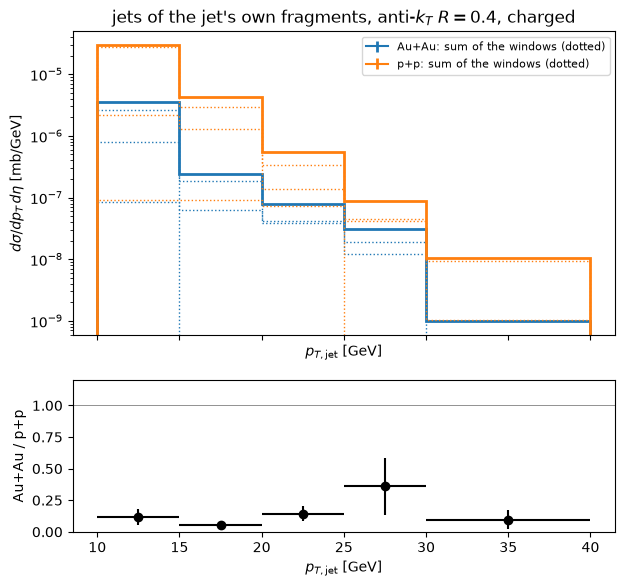

In [11]:
pt_edges = np.array([10, 15, 20, 25, 30, 40.0])

def window_spectra(name, edges=pt_edges):
    """Per window: jets per event (mean over each event's samples), and the error from the spread
    of the events. -> list of hist.Hist (Weight storage), one per window."""
    d, rd = FJ[name], FJ[name]["reader"]
    out = []
    for k in range(3):
        g = rd.pthat_bin_events(k)
        per_event = np.zeros((len(g), len(edges) - 1))
        row = {int(e): i for i, e in enumerate(g)}
        sel = np.isin(d["event"], g)
        for e, x in zip(d["event"][sel], d["pt"][sel]):
            j = np.searchsorted(edges, x, side="right") - 1
            if 0 <= j < len(edges) - 1:
                per_event[row[int(e)], j] += 1.0 / rd.n_frag(int(e))
        h = hist.Hist(hist.axis.Variable(edges, label=r"$p_{T,\mathrm{jet}}$ [GeV]"), storage=hist.storage.Weight())
        h.view().value = per_event.mean(axis=0)
        h.view().variance = per_event.var(axis=0, ddof=1) / len(g)
        out.append(h)
    return out

W = {name: window_spectra(name) for name in FJ}
S = {name: sum((W[name][k] * SIGMA[k] for k in range(3)), start=W[name][0] * 0) for name in FJ}
width = np.diff(pt_edges) * 2 * JET_ETA                        # per GeV and per unit of eta

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 6.5), sharex=True, height_ratios=[2, 1])
for c, name in enumerate(FJ):
    for k in range(3):
        mh.histplot(W[name][k] * SIGMA[k] / width, ax=ax, flow="none", color=f"C{c}", ls=":", lw=1)
    mh.histplot(S[name] / width, ax=ax, flow="none", color=f"C{c}", lw=2, label=f"{name}: sum of the windows (dotted)")
ax.set(yscale="log", ylabel=r"$d\sigma/dp_T\,d\eta$ [mb/GeV]", title=r"jets of the jet's own fragments, anti-$k_T$ $R=0.4$, charged")
ax.legend(fontsize=8)
ratio = S["Au+Au"].values() / S["p+p"].values()
ratio_err = ratio * np.sqrt(S["Au+Au"].variances() / S["Au+Au"].values()**2 + S["p+p"].variances() / S["p+p"].values()**2)
ax2.errorbar(S["p+p"].axes[0].centers, ratio, ratio_err, xerr=np.diff(pt_edges) / 2, fmt="o", color="k")
ax2.axhline(1, color="0.5", lw=0.6)
ax2.set(ylim=(0, 1.2), ylabel="Au+Au / p+p", xlabel=r"$p_{T,\mathrm{jet}}$ [GeV]")
sig_aa = np.array([aa.pthat_bin_sigma(k)[0] for k in range(3)])
ratio_own = sum(W["Au+Au"][k].values() * sig_aa[k] for k in range(3)) / S["p+p"].values()
share_pp = np.array([W["p+p"][k].values() * SIGMA[k] for k in range(3)]) / S["p+p"].values()
for i in range(len(ratio)):
    print(f"{pt_edges[i]:.0f}-{pt_edges[i + 1]:.0f} GeV: Au+Au / p+p = {ratio[i]:.2f} +- {ratio_err[i]:.2f}"
          f"   (with Au+Au's own cross sections {ratio_own[i]:.2f});  p+p windows' shares {share_pp[:, i].round(2)}")

**What to notice.**

- **Each window dominates its own range of jet $p_T$**, as the hadrons did in tutorial 05: the lowest
  below 20 GeV, the middle one at 20–30 GeV, the highest above 30 GeV (the shares are printed).
- **The jets of the fragments are suppressed about tenfold in Au+Au.** The ratio scatters between
  about 0.06 and 0.36, with errors of the same size as the scatter, around a typical value of 0.1.
  The jets lose a large part of their energy to the fluid: about 40 GeV per event (tutorial 05,
  section 5). On a spectrum that falls by almost an order of magnitude every 5 GeV, a shift of several
  GeV removes most of the jets at a fixed $p_T$.
- **The cross sections matter at the level of up to 20 %.** With Au+Au's own, imprecise cross sections the
  ratio moves by up to 0.02 (printed). With the same cross sections in numerator and denominator, the
  ratio depends only on the yields per event.

**Why only illustrative.** Each window has 40 Au+Au events, and at a given jet $p_T$ only a few of them
have a jet. The ten fragmentations of an event are not independent, so the errors above come from the
spread of the events. This is also not the measurable jet suppression: the jets here have no medium
response (it adds back about 1 GeV in the cone, section 7), and no background fluctuations or fakes.
With these statistics the full-event version (section 4) would be dominated by fakes. The ratio says
how strongly the model's jets lose energy, not what an experiment would see.

## 6. Substructure: the SoftDrop $z_g$

SoftDrop looks inside a jet. It reclusters the jet's constituents with the Cambridge/Aachen
algorithm (ordered in angle) and undoes the clustering from the top. At each step the two branches
have the momentum fraction $z = \min(p_{T,1}, p_{T,2})/(p_{T,1}+p_{T,2})$. Branches with
$z < z_\text{cut} = 0.1$ are dropped, and the first pair that passes defines $z_g$ (and its angle
$R_g$). $z_g$ is close to the splitting function of the hardest splitting of the parton. Energy loss
can change it: a medium that removes soft, wide branches, or resolves the two prongs separately,
shifts $z_g$.

The array interface wraps fjcontrib's SoftDrop. We give it the constituents of each jet above
20 GeV (jets of the fragments alone, as in section 5) as one entry, reclustered with C/A and asked
for one exclusive jet.

**One window, not the sum.** In p+p, about 10 of the jets above 20 GeV come from the lowest window.
Weighted with $\sigma_k$, each would count about 1,000 times as much as a jet of the highest window,
and these few jets would decide the weighted mean, like the single hadron of the spike in tutorial 05. So we compare the jets of one window, p̂T 30–50 GeV, where Au+Au has
almost all its jets above 20 GeV. Within a window every jet has the same weight. The error of the
mean comes from leaving out one event at a time (jackknife): the jets of one event's fragmentations
are not independent.

Au+Au: 110 jets above 20 GeV from 33 events; groomed 95%; <z_g> = 0.229 +- 0.010
p+p: 9946 jets above 20 GeV from 1469 events; groomed 94%; <z_g> = 0.244 +- 0.001


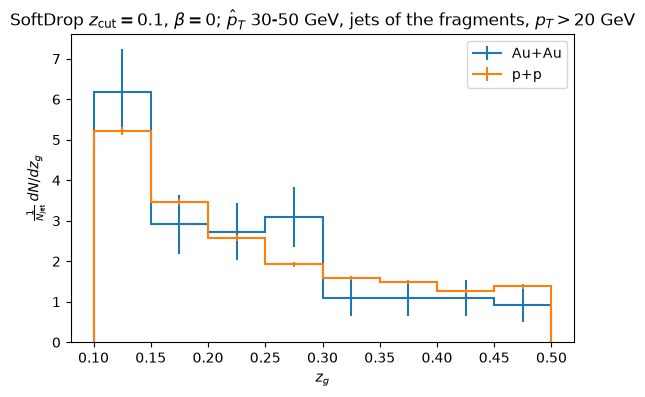

In [12]:
CA = fj.JetDefinition(fj.cambridge_algorithm, 1.0)
zg_edges = np.linspace(0.1, 0.5, 9)

def jackknife_mean(x, event):
    """Mean of x and its error from leaving out one event at a time."""
    ids, inv = np.unique(event, return_inverse=True)
    s, n = np.bincount(inv, weights=x), np.bincount(inv)
    loo = (s.sum() - s) / (n.sum() - n)                     # the mean without each event
    return x.mean(), np.sqrt((len(ids) - 1) / len(ids) * np.sum((loo - loo.mean()) ** 2))

ZG = {}
fig, ax = plt.subplots(figsize=(6.5, 4))
for name in FJ:
    d, rd = FJ[name], FJ[name]["reader"]
    sel = (d["pt"] > 20.0) & np.isin(d["event"], rd.pthat_bin_events(2))
    cs = fj.ClusterSequence(ak.to_packed(d["cons"][sel]), CA)
    zg = cs.exclusive_jets_softdrop_grooming(njets=1, beta=0.0, symmetry_cut=0.1, R0=R).symmetrysoftdrop.to_numpy()
    h = hist.Hist(hist.axis.Variable(zg_edges, label=r"$z_g$"), storage=hist.storage.Weight())
    h.fill(zg)                                     # ungroomed jets (z_g = -1) fall outside the axis
    mh.histplot(h / len(zg) / np.diff(zg_edges), ax=ax, label=name, flow="none")
    groomed = zg > 0
    ZG[name] = jackknife_mean(zg[groomed], d["event"][sel][groomed])
    print(f"{name}: {sel.sum()} jets above 20 GeV from {len(np.unique(d['event'][sel]))} events; "
          f"groomed {groomed.mean():.0%}; <z_g> = {ZG[name][0]:.3f} +- {ZG[name][1]:.3f}")
ax.set(ylabel=r"$\frac{1}{N_\mathrm{jet}}\,dN/dz_g$",
       title=r"SoftDrop $z_\mathrm{cut}=0.1$, $\beta=0$; $\hat p_T$ 30-50 GeV, jets of the fragments, $p_T>20$ GeV")
ax.legend();

**What to notice.**

- **In p+p, $z_g$ falls from the cut at 0.1 towards 0.5.** The hardest splitting of a parton is
  mostly asymmetric: the QCD splitting function grows like $1/z$ at small $z$.
- **Au+Au has the same shape within its errors.** The means differ by 0.015 ± 0.010, 1.5 standard
  deviations: with 110 jets from 33 events no change of $z_g$ can be seen. (The error bars of the bins
  count jets as independent, which they are not; for Au+Au they are too small.)
- **Selection matters.** At the same jet $p_T$ in the same window, the Au+Au jets come from the
  partons that lost the least energy, which biases any comparison at fixed jet $p_T$.

In a measurement, the background would have to be removed particle by particle before grooming
(for example with fjcontrib's ConstituentSubtractor, which the Python bindings do not wrap). The jets
of the fragments alone avoid that here.

## 7. The medium response inside the jet

The energy a jet loses does not disappear: the fluid picks it up (tutorial 06), and it comes out as
extra soft hadrons around the jet (tutorial 07). A jet finder does not know which hadrons are which,
so part of this **medium response** ends up inside the jet. Here it is $\langle$`bulk_jet` $-$
`bulk_bg`$\rangle$: the charged $p_T$ at a distance $\Delta R$ from the leading parton, per event, next to
that of the jet's own fragments. The reader averages all oversamples of all 120 events; we go out to
$\Delta R = 0.9$, where the cone around a parton at $|y| < 0.6$ still lies inside $|\eta| < 1.5$.

2 s
inside Delta R < 0.4: medium response 1.12 +- 0.19 GeV, jet fragments 6.32 GeV
inside Delta R < 0.9: medium response 3.05 +- 0.43 GeV, jet fragments 7.35 GeV
the wake raises rho: rho(full) - rho(bkg + jet) = +0.74 +- 0.15 GeV per unit area -> +0.37 GeV more subtracted from a jet of area pi R^2
jets (section 3): full - embedded = +0.83 +- 0.49 GeV


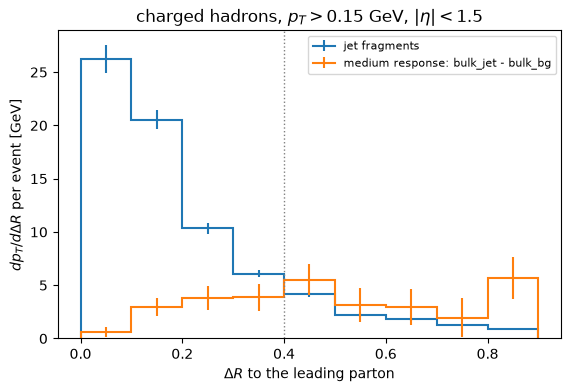

In [13]:
def lead_axis(info):
    """eta and phi of the event's hardest shower initiator."""
    ini = info.initiators()
    px, py, pz = ini[np.argmax(np.hypot(ini[:, 3], ini[:, 4])), 3:6]
    return np.arcsinh(pz / np.hypot(px, py)), np.arctan2(py, px)

def dR_lead(ev, info):
    eta0, phi0 = lead_axis(info)
    return np.hypot(ev.eta - eta0, np.mod(ev.phi - phi0 + np.pi, 2 * np.pi) - np.pi)

clustered = lambda ev, info: ev.charged & (np.abs(ev.eta) < ETA_MAX) & (ev.pt > PT_MIN)
r_edges = np.linspace(0, 0.9, 10)
t0 = time.time()
wake, wake_err = aa.jet_minus_background(dR_lead, r_edges, mask=clustered, weights="pt")
frag, frag_err = aa.hist("jet_frag", dR_lead, r_edges, mask=clustered, weights="pt")
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 4))
dr = np.diff(r_edges)
for vals, errs, label in ((frag, frag_err, "jet fragments"), (wake, wake_err, "medium response: bulk_jet - bulk_bg")):
    h = hist.Hist(hist.axis.Variable(r_edges, label=r"$\Delta R$ to the leading parton"), storage=hist.storage.Weight())
    h.view().value, h.view().variance = vals / dr, (errs / dr) ** 2
    mh.histplot(h, ax=ax, label=label, flow="none")
ax.axvline(R, color="0.5", ls=":", lw=1)
ax.axhline(0, color="0.5", lw=0.6)
ax.set(ylabel=r"$dp_T/d\Delta R$ per event [GeV]", title=r"charged hadrons, $p_T > 0.15$ GeV, $|\eta| < 1.5$")
ax.legend(fontsize=8)
inside = r_edges[1:] <= R + 1e-9
print(f"inside Delta R < {R}: medium response {wake[inside].sum():.2f} +- {np.sqrt((wake_err[inside]**2).sum()):.2f} GeV,"
      f" jet fragments {frag[inside].sum():.2f} GeV")
print(f"inside Delta R < {r_edges[-1]}: medium response {wake.sum():.2f} +- {np.sqrt((wake_err**2).sum()):.2f} GeV,"
      f" jet fragments {frag.sum():.2f} GeV")
drho = rho_rec["full"] - rho_rec["emb"]          # the same fragments: the wake's effect on rho
print(f"the wake raises rho: rho(full) - rho(bkg + jet) = {drho.mean():+.2f} +- {drho.std() / np.sqrt(len(drho)):.2f}"
      f" GeV per unit area -> {drho.mean() * np.pi * R**2:+.2f} GeV more subtracted from a jet of area pi R^2")
print(f"jets (section 3): full - embedded = {diff.mean():+.2f} +- {diff.std() / np.sqrt(len(diff)):.2f} GeV")

**What to notice.**

- **The fragments sit in the core, the medium response does not.** The fragments' $p_T$ falls steeply
  with $\Delta R$. The medium response is spread out: per unit of $\Delta R$ it is roughly flat from 0.1
  to 0.9, small only in the very core.
- **The cone of a jet with $R = 0.4$ catches only part of it**: about 1.1 GeV, on top of about 6.3 GeV
  of charged fragments of the leading parton. Out to $\Delta R = 0.9$ it is about 3 GeV. Larger jets
  get back more of the lost energy, so jet suppression depends on $R$.
- **ρA subtraction removes some of it.** The wake is spread over the whole event, so it also raises
  ρ, by about 0.7 GeV per unit area: about 0.4 GeV more is subtracted from each jet as if it were
  background. What remains in a subtracted jet, about 1.1 − 0.4 = 0.7 GeV, agrees with the 0.8 ± 0.5
  GeV that the jets of section 3 gained between the embedding and the full event.

The errors here are those of independent sampling. Tutorial 07 measures the same difference with
correlated sampling, about 8 times more precisely, and maps its shape around the jet.

### Check your result

FastJet places its ghosts with a small random jitter, and the Python bindings cannot set its seed. A
fresh kernel repeats the same sequence, but clustering in another order, or another FastJet build,
gives slightly different areas and ρ. Those checks have tolerances; the rest is exact.

In [14]:
import json
exp = json.load(open("expected/08_jets_fastjet.json"))
np.testing.assert_allclose([len(FJ["Au+Au"]["pt"]), len(FJ["p+p"]["pt"])], exp["n_frag_jets"])
np.testing.assert_allclose(ratio, exp["ratio_aa_pp"], rtol=1e-6)
np.testing.assert_allclose([ZG["Au+Au"][0], ZG["p+p"][0]], exp["mean_zg"], rtol=1e-6)
np.testing.assert_allclose(wake[inside].sum(), exp["medium_pt_in_cone"], rtol=1e-6)
np.testing.assert_allclose(rho_rec["bkg"].mean(), exp["rho_bkg"], rtol=0.01)
np.testing.assert_allclose(cones.std(), exp["random_cone_width"], rtol=0.05)
np.testing.assert_allclose(d_emb.mean(), exp["dpt_emb_mean"], atol=0.5)
print("All checks pass.")

All checks pass.


## Exercises

1. **All oversamples.** Set `N_OS = 10` and rerun section 3. Which results change by more than their
   errors? How long does it take?
2. **Jet radius.** Repeat sections 3 and 7 with $R = 0.2$ and $R = 0.6$ (change `R`, and with it
   `JET_ETA` and the selectors). How do the random-cone width and the medium response in the cone
   scale with the area $\pi R^2$?
3. **$R_g$.** In section 6, also take `deltaRsoftdrop` and compare the groomed radius $R_g$ in Au+Au
   and p+p.
4. **The suppression per window.** Compute the Au+Au / p+p ratio of the jet yields for each p̂T window
   separately, without cross sections. Which window is suppressed most at the same jet $p_T$, and why
   does that not mean its partons lost the most energy?

## Next steps

- Conventions, the array interface, ghosts by hand, and complete campaign analyses: [Jets with FastJet](https://jhputschke.github.io/js-contrib/analysis/jets/).
- The longer notebooks on areas, ρ and substructure: `contribs/PyJetscape/example/analysis/tutorials/jet_fastjet.ipynb` and `jet_fastjet_awkward.ipynb` in js-contrib.
- FastJet in C++ on the ROOT files: tutorial 10 and [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/#5-fastjet-in-c).
- The wake around the jet, precisely: tutorial 07 and [Hydro and hadrons together](https://jhputschke.github.io/js-contrib/analysis/hydro-hadrons/).